# Turtle Breakout 18 — diagnostic: is BTC mean-reverting while the turtle is out of the market?

Pre-registration: `discussions/Turtle_Breakout/020_claude_tb18_preregistration.md`. Code: `turtle_flat_diag.py`; data: the TB 17 BTC-USD daily file.

Day $t$ is **IN** if the TB 17 turtle (long only, TB 01 rules) holds a long at its close, **FLAT** otherwise. On FLAT days: variance ratios of the next $q$ days ($q$ = 2, 5, 10, 20), autocorrelations, the reversal spreads (top − bottom quintile of the past 1- and 5-day return → next 1 and 5 days) and a z-score table, against 2,000 permutations of the returns.
**MR_PRESENT** only if some VR(q) < 1 with p < 0.0125 **and** a reversal spread (1-day or 5-day) < 0 with p < 0.025.

Environment: `TB17_DATA` (default `<parent of DERIBIT_DATA_ROOT>/Stocks/tb17/btc_daily.parquet`), `TB18_SYNTHETIC=1`.

In [1]:
import os, sys, json, subprocess, tempfile, warnings, platform
from dataclasses import replace
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from dotenv import load_dotenv
warnings.filterwarnings('ignore', category=RuntimeWarning)
pd.set_option('display.width', 250); pd.set_option('display.max_columns', 40)
ROOT = Path.cwd().resolve()
while ROOT != ROOT.parent and not (ROOT / 'src' / 'data_engineering').is_dir(): ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / 'src')); load_dotenv(ROOT / '.env')
from data_engineering.modeling import turtle_breakout as tb, turtle_reverse as tr, turtle_stocks as tk, turtle_stock_accounts as ta, turtle_btc_history as bh, turtle_flat_diag as fd

SYNTHETIC = os.getenv('TB18_SYNTHETIC', '0') == '1'
DP = fd.DParams(); BP = bh.BParams()
P = replace(tb.Params(), min_bar_share=0.0, funding=False, fee=BP.side_cost - tb.Params().slip); RP = replace(tr.RParams(), side_cost=BP.side_cost)
if SYNTHETIC:
    OUT = Path(tempfile.mkdtemp(prefix='tb18-')) / '18'; DP = replace(DP, n_perm=200)
    d, _ = tk.synthetic_daily(4400, seed=18, vol=0.04, gap=0.0, steps=48, drift=0.0005); d.index = pd.date_range('2014-09-17', periods=len(d), freq='D'); DAILY = d
else:
    OUT = ROOT / 'notebooks' / 'Turtle_Breakout' / '18'
    root = Path(os.environ['DERIBIT_DATA_ROOT']).parent
    DATA_FILE = Path(os.environ.get('TB17_DATA', str(root / 'Stocks' / 'tb17' / 'btc_daily.parquet')))
    if not DATA_FILE.exists():
        sys.path.insert(0, str(ROOT / 'tools')); import download_tb17_btc as dl; DATA_FILE = dl.download(DATA_FILE.parent)
    RAW = pd.read_parquet(DATA_FILE); RAW['date'] = pd.to_datetime(RAW['date']).dt.tz_localize(None).dt.normalize()
    DAILY = RAW.set_index('date')[['open', 'high', 'low', 'close']].sort_index(); DAILY = DAILY[~DAILY.index.duplicated()].dropna(); DAILY = DAILY[(DAILY > 0).all(axis=1)]
OUT.mkdir(parents=True, exist_ok=True)
env = os.environ.copy(); env['PYTHONPATH'] = str(ROOT / 'src') + os.pathsep + env.get('PYTHONPATH', '')
chk = subprocess.run([sys.executable, '-m', 'unittest', 'discover', '-s', 'tests', '-p', 'test_turtle_flat_diag.py'], cwd=str(ROOT), env=env, capture_output=True, text=True)
print(chk.stderr.strip().splitlines()[-1]); assert chk.returncode == 0
print('BTC-USD', DAILY.index[0].date(), '->', DAILY.index[-1].date(), len(DAILY)); print(json.dumps(fd.registration(DP), indent=1))

OK
BTC-USD 2014-09-17 -> 2026-10-27 4424
{
 "n_perm": 2000,
 "rev_k": 5,
 "rev_h": 5,
 "z_window": 20,
 "alpha_vr": 0.0125,
 "alpha_rev": 0.05,
 "seed": 20261030,
 "status": "PREREGISTERED_TB020",
 "version": "TB18-0.1.0",
 "qs": [
  2,
  5,
  10,
  20
 ],
 "decision": "FLAT days: min_q p(VR<1) < 0.0125 AND min_k p(REV(k,k)<0) < 0.025, k = 1, 5 -> MR_PRESENT; otherwise NO_MEAN_REVERSION"
}


## 1. Turtle state and trend labels

In [2]:
W = bh.run_window(DAILY, '2014-09-17', None, P, RP, ta.AParams(), 0, np.random.default_rng(0))
TR = W['trades'].query("kind == 'long'").copy()
TR.loc[TR.open_at_end, 'exit'] = DAILY.index[-1] + pd.Timedelta(days=1)
start = W['long'].index[0]
close = DAILY.close; r = np.log(close).diff().to_numpy()
STATE = fd.turtle_state(DAILY.index, TR, start); TREND = fd.trend_label(close)
valid = STATE.notna().to_numpy() & np.isfinite(r)
MASKS = {'all': valid, 'in': valid & (STATE == 'in').to_numpy(), 'flat': valid & (STATE == 'flat').to_numpy()}
for lab in ('down', 'range', 'up'):
    MASKS[f'flat_{lab}'] = MASKS['flat'] & (TREND == lab).to_numpy()
COMP = pd.DataFrame({'days': {k: int(m.sum()) for k, m in MASKS.items()}}); COMP['share_of_all'] = COMP.days / COMP.loc['all', 'days']
display(COMP.round(3))
sp = (STATE == 'flat').astype(int); runs = sp.groupby((sp != sp.shift()).cumsum()).agg(['first', 'size']); fl = runs[runs['first'] == 1]['size']
print(f"flat spells: {len(fl)}, median {fl.median():.0f} days, mean {fl.mean():.0f}, longest {fl.max()}")
print('flat days by year:'); display((STATE == 'flat').groupby(DAILY.index.year).mean().round(2).to_frame('share_flat').T)

,days,share_of_all
all,4394,1.000
in,1816,0.413
flat,2578,0.587
flat_down,1529,0.348
flat_range,578,0.132
flat_up,452,0.103


flat spells: 84, median 25 days, mean 31, longest 109
flat days by year:


date,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
share_flat,0.64,0.58,0.45,0.38,0.79,0.65,0.48,0.61,0.73,0.48,0.51,0.73,0.58


## 2. Statistics by state, with permutation nulls

In [3]:
STATS = {}
for k, m in MASKS.items():
    null = fd.permutation(r, m, replace(DP, seed=DP.seed + len(STATS)))
    STATS[k] = fd.state_stats(r, m, null)
ST = pd.DataFrame(STATS).T
display(ST[['days', 'ann_drift_pct', 'ann_vol_pct'] + [f'VR{q}' for q in fd.QS] + [f'p_VR{q}_below' for q in fd.QS] + ['REV11', 'p_REV11_below', 'REV55', 'p_REV55_below']].round(4))
display(ST[[f'AC{k}' for k in range(1, 11)]].round(3))
print('approx. 95% band for one AC on FLAT days: +/-', round(1.96 / np.sqrt(ST.loc['flat', 'days']), 3))

,days,ann_drift_pct,ann_vol_pct,VR2,VR5,VR10,VR20,p_VR2_below,p_VR5_below,p_VR10_below,p_VR20_below,REV11,p_REV11_below,REV55,p_REV55_below
all,4394.0,44.4496,66.2875,0.9748,0.9884,1.0221,1.0894,0.0545,0.3728,0.6947,0.8956,-0.0001,0.4988,0.0107,0.9590
in,1816.0,109.1063,61.8582,1.0944,1.1279,1.2409,1.2956,1.0000,0.9875,0.9975,0.9895,0.0084,0.9995,0.0189,0.9775
flat,2578.0,-1.1137,69.1394,0.9048,0.9004,0.8859,0.9569,0.0005,0.0140,0.0510,0.3688,-0.0049,0.0120,-0.0032,0.3633
flat_down,1529.0,-9.8188,74.6354,0.9025,0.8812,0.8166,0.7679,0.0040,0.0295,0.0195,0.0310,-0.0056,0.0315,0.0087,0.8301
flat_range,578.0,-9.1596,58.9855,0.8379,0.8078,0.9301,1.3090,0.0110,0.0425,0.3378,0.9205,-0.0047,0.1589,-0.0238,0.0535
flat_up,452.0,48.4548,62.0395,0.9927,1.0913,1.1182,1.4563,0.4878,0.7616,0.7466,0.9685,-0.0053,0.1594,-0.0062,0.3788


,AC1,AC2,AC3,AC4,AC5,AC6,AC7,AC8,AC9,AC10
all,-0.025,0.013,0.011,0.012,0.011,0.035,-0.018,-0.027,0.001,0.037
in,0.082,-0.001,0.001,0.003,0.056,0.009,-0.019,-0.027,0.017,0.047
flat,-0.091,0.012,0.008,0.010,-0.019,0.045,-0.022,-0.032,-0.014,0.027
flat_down,-0.090,0.009,0.019,0.028,-0.019,0.055,-0.044,-0.053,-0.028,0.001
flat_range,-0.072,0.052,-0.088,-0.013,-0.080,-0.116,0.046,-0.017,0.008,0.014
flat_up,-0.128,-0.029,0.056,-0.047,0.024,0.126,-0.024,0.032,0.003,0.118


approx. 95% band for one AC on FLAT days: +/- 0.039


## 3. Decision (FLAT days)

In [4]:
DEC = fd.decide(STATS['flat'], DP)
DEC['by_trend_reported'] = {k: fd.decide(STATS[k], DP) for k in ('flat_down', 'flat_range', 'flat_up')}
print(json.dumps(DEC, indent=1, default=float))

{
 "min_p_VR_below": 0.0004997501249375312,
 "VR_pass": true,
 "REV11": -0.004942726466622935,
 "REV55": -0.0031607127362775276,
 "min_p_REV": 0.01199400299850075,
 "REV_pass": true,
 "verdict": "MR_PRESENT",
 "by_trend_reported": {
  "flat_down": {
   "min_p_VR_below": 0.00399800099950025,
   "VR_pass": true,
   "REV11": -0.005577336890679609,
   "REV55": 0.008676551973546614,
   "min_p_REV": 0.031484257871064465,
   "REV_pass": false,
   "verdict": "NO_MEAN_REVERSION"
  },
  "flat_range": {
   "min_p_VR_below": 0.010994502748625687,
   "VR_pass": true,
   "REV11": -0.004690354652116225,
   "REV55": -0.02376328836683808,
   "min_p_REV": 0.05347326336831584,
   "REV_pass": false,
   "verdict": "NO_MEAN_REVERSION"
  },
  "flat_up": {
   "min_p_VR_below": 0.4877561219390305,
   "VR_pass": false,
   "REV11": -0.005279123771385109,
   "REV55": -0.006163465513308669,
   "min_p_REV": 0.15942028985507245,
   "REV_pass": false,
   "verdict": "NO_MEAN_REVERSION"
  }
 }
}


## 4. Reported: reversal and z-score tables

In [5]:
for k in ('flat', 'in', 'flat_range', 'flat_down'):
    for kk in (1, 5):
        s, T = fd.rev(r, MASKS[k], kk, kk); print(f'{k}: next-{kk}-day log return by past-{kk}-day quintile (spread {s:+.4f})'); display(T.round(4))
for k in ('flat', 'in'):
    print(f'{k}: next-5-day log return by z20 bucket'); display(fd.z_table(close, r, MASKS[k], DP.z_window, 5).round(4))

flat: next-1-day log return by past-1-day quintile (spread -0.0049)


,n,past_mean,fwd_mean,fwd_up
q,,,,
0,516,-0.0510,0.0035,0.5814
1,515,-0.0116,-0.0006,0.5243
2,515,-0.0006,-0.0014,0.5029
3,515,0.0095,-0.0003,0.4757
4,516,0.0419,-0.0015,0.4496


flat: next-5-day log return by past-5-day quintile (spread -0.0032)


,n,past_mean,fwd_mean,fwd_up
q,,,,
0,515,-0.1264,-0.0013,0.5437
1,514,-0.0435,0.0029,0.5545
2,515,-0.0109,-0.0003,0.5223
3,514,0.0125,0.0049,0.5370
4,515,0.0698,-0.0045,0.4718


in: next-1-day log return by past-1-day quintile (spread +0.0084)


,n,past_mean,fwd_mean,fwd_up
q,,,,
0,364,-0.0321,-0.0016,0.5412
1,363,-0.0061,0.0028,0.5647
2,363,0.0037,0.0023,0.5620
3,363,0.0158,0.0045,0.5179
4,363,0.0502,0.0068,0.5510


... (10 outputs left out)

flat: next-5-day log return by z20 bucket


,n,fwd_mean,fwd_up
z,,,
"(-inf, -2.0]",679,0.0007,0.5817
"(-2.0, -1.0]",559,-0.0027,0.5045
"(-1.0, 0.0]",677,0.0023,0.5258
"(0.0, 1.0]",405,0.0002,0.4617
"(1.0, 2.0]",201,0.0035,0.5373
"(2.0, inf]",52,-0.0072,0.4808


in: next-5-day log return by z20 bucket


,n,fwd_mean,fwd_up
z,,,
"(-inf, -2.0]",1,0.0726,1.0000
"(-2.0, -1.0]",3,-0.0406,0.0000
"(-1.0, 0.0]",90,0.0069,0.5444
"(0.0, 1.0]",227,0.0048,0.5551
"(1.0, 2.0]",373,0.0001,0.4960
"(2.0, inf]",1122,0.0215,0.5936


## 5. Figures

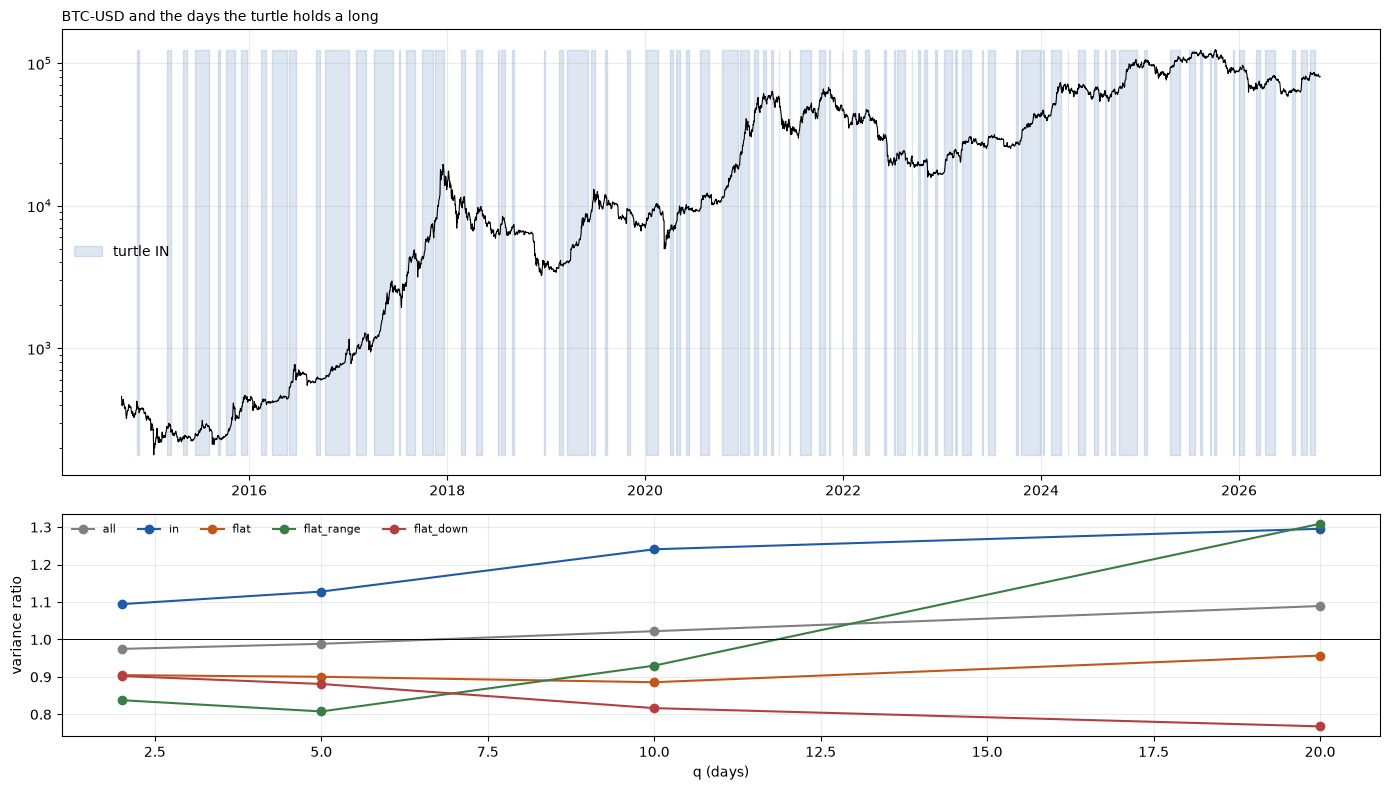

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), gridspec_kw={'height_ratios': [2, 1]})
axes[0].plot(close.index, close, color='k', lw=0.8); axes[0].set_yscale('log')
inn = (STATE == 'in').to_numpy()
axes[0].fill_between(close.index, close.min(), close.max(), where=inn, color='#1f5aa6', alpha=0.15, label='turtle IN')
axes[0].legend(frameon=False); axes[0].set_title('BTC-USD and the days the turtle holds a long', loc='left', fontsize=10)
for k, col in (('all', '0.5'), ('in', '#1f5aa6'), ('flat', '#c2571a'), ('flat_range', '#3a7d44'), ('flat_down', '#b33f40')):
    axes[1].plot(fd.QS, [STATS[k][f'VR{q}'] for q in fd.QS], marker='o', color=col, label=k)
axes[1].axhline(1, color='k', lw=0.7); axes[1].set_xlabel('q (days)'); axes[1].set_ylabel('variance ratio'); axes[1].legend(frameon=False, fontsize=8, ncol=5)
for a in axes: a.grid(alpha=0.25)
plt.tight_layout(); plt.show()

## 6. Save

In [7]:
ST.to_csv(OUT / '18_stats_by_state.csv'); COMP.to_csv(OUT / '18_composition.csv')
pd.DataFrame({'state': STATE, 'trend': TREND}).to_csv(OUT / '18_state_daily.csv')
(OUT / '18_decision.json').write_text(json.dumps({'decision': DEC, 'registration': fd.registration(DP), 'synthetic': SYNTHETIC}, indent=1, default=float))
git = subprocess.run(['git', 'rev-parse', '--short', 'HEAD'], cwd=str(ROOT), capture_output=True, text=True).stdout.strip()
(OUT / '18_manifest.json').write_text(json.dumps({'version': fd.VERSION, 'git': git, 'python': platform.python_version(), 'created_utc': pd.Timestamp.now('UTC').isoformat(), 'synthetic': SYNTHETIC}, indent=1))
print('saved to', OUT); print('VERDICT:', DEC['verdict'])

saved to D:\Projects\deribit_market_data\notebooks\Turtle_Breakout\18
VERDICT: MR_PRESENT
